In [1]:
# this notebook is to learn pytorch from scratch and to implement various types of NN in a general format !!

In [2]:
import torch
cuda = torch.cuda.is_available()
print(cuda)

True


In [3]:
device = torch.cuda.get_device_name(0)
print(device)

NVIDIA GeForce GTX 1650


In [4]:
lst = [[1,2,3],[4,5,6],[7,8,9]]
a = torch.tensor(lst)
print("a : ", a)
print("a.data : ", a.data)

a :  tensor([[1, 2, 3],
        [4, 5, 6],
        [7, 8, 9]])
a.data :  tensor([[1, 2, 3],
        [4, 5, 6],
        [7, 8, 9]])


In [5]:
print(a[0]) # the individual element of a tensor is also a tensor !

tensor([1, 2, 3])


In [6]:
print(a[0].data)

tensor([1, 2, 3])


In [7]:
b = torch.tensor([1,3,4], dtype = torch.float)
print(b)
print(b.data)
print(b[0])

tensor([1., 3., 4.])
tensor([1., 3., 4.])
tensor(1.)


In [8]:
print(b.mean(), b.std())

tensor(2.6667) tensor(1.5275)


In [9]:
a.view(9,-1)

tensor([[1],
        [2],
        [3],
        [4],
        [5],
        [6],
        [7],
        [8],
        [9]])

In [10]:
a.view(-1,9)

tensor([[1, 2, 3, 4, 5, 6, 7, 8, 9]])

In [11]:
# view() function returns a new tensor but shares/points to the same memory
# so any changes to original or viewed tensor will change the memory and 
# will reflect in all the views created by view()

In [12]:
c = a.view(-1,9)
c

tensor([[1, 2, 3, 4, 5, 6, 7, 8, 9]])

In [13]:
c[0][2] = 10
c

tensor([[ 1,  2, 10,  4,  5,  6,  7,  8,  9]])

In [14]:
# since c was a view of a, so a will also change
a

tensor([[ 1,  2, 10],
        [ 4,  5,  6],
        [ 7,  8,  9]])

In [15]:
d = torch.rand(2,3,5) # uniform dist. over 0 to 1 !
e = torch.randn(2,3,5) # normal dist. with 0 mean and 1 stdev.
# 2 channels, each channel has 3 rows, each row has 5 columns :--> 3D tensor
print(d)
print(e)

tensor([[[0.7822, 0.7334, 0.9913, 0.7824, 0.0658],
         [0.4482, 0.9486, 0.1507, 0.3537, 0.5631],
         [0.2082, 0.5462, 0.1293, 0.2890, 0.1464]],

        [[0.7588, 0.0545, 0.6918, 0.7127, 0.1362],
         [0.0886, 0.5495, 0.5797, 0.8712, 0.5351],
         [0.3656, 0.8974, 0.6919, 0.3742, 0.8526]]])
tensor([[[ 0.1326, -1.0879,  0.3494,  1.4549,  0.5477],
         [ 1.4682, -2.1680, -1.6538, -0.0847,  2.5626],
         [-0.0152, -1.1624, -1.2574,  2.7810, -1.1454]],

        [[-1.1874,  0.3425, -0.0601, -1.7027, -0.1772],
         [ 0.1478, -0.8009, -2.1892, -0.5587,  1.3615],
         [ 0.2617,  1.3245,  2.1001, -0.4776, -1.1609]]])


In [16]:
f = torch.randint(6,10,(5,3,2)) # random integer between 6 and 10 of dims (5,3,2)
f

tensor([[[8, 6],
         [8, 8],
         [6, 8]],

        [[6, 7],
         [6, 7],
         [9, 6]],

        [[7, 6],
         [7, 6],
         [6, 6]],

        [[6, 7],
         [6, 8],
         [6, 7]],

        [[8, 7],
         [6, 7],
         [6, 8]]])

In [17]:
g = torch.ones(3,3)
h = torch.zeros(3,3)
print(g)
print(h) 

tensor([[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]])
tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])


In [18]:
add = torch.add(torch.ones(3,5), torch.rand(3,5))
add

tensor([[1.9641, 1.3657, 1.0599, 1.1165, 1.6229],
        [1.8019, 1.7444, 1.7677, 1.9485, 1.6085],
        [1.0203, 1.9822, 1.3094, 1.3536, 1.5615]])

In [19]:
add.numpy() # from pytorch tensor to numpy array
import numpy as np
a = np.ones(6)
print("numpy array : ", a)
b = torch.from_numpy(a) # from numpy array to pytorch tensor
b

numpy array :  [1. 1. 1. 1. 1. 1.]


tensor([1., 1., 1., 1., 1., 1.], dtype=torch.float64)

In [20]:
x = torch.ones(2,3,requires_grad = True)
y = torch.randn(2,3,requires_grad = True)
z = x+y
print(z.grad_fn)

In [21]:
out = z.mean()
print(z)
print(out)

tensor([[ 0.1864,  2.0942,  0.8018],
        [ 0.5380, -0.3922,  1.4671]], grad_fn=<AddBackward0>)
tensor(0.7825, grad_fn=<MeanBackward0>)


In [22]:
out.backward()
print(x.grad)

tensor([[0.1667, 0.1667, 0.1667],
        [0.1667, 0.1667, 0.1667]])


In [23]:
import torch.nn as nn

In [24]:
layer = nn.Linear(5,5)
print(layer)
print(layer.weight)
print(layer.bias)

Linear(in_features=5, out_features=5, bias=True)
Parameter containing:
tensor([[-0.1229, -0.0946,  0.1269, -0.1298,  0.2219],
        [ 0.1589,  0.3134, -0.0305, -0.1107,  0.3362],
        [-0.4019, -0.2307, -0.3053, -0.1267, -0.0054],
        [-0.0795, -0.1484, -0.1854, -0.1018,  0.3367],
        [ 0.3274,  0.2201,  0.3509,  0.3783, -0.1317]], requires_grad=True)
Parameter containing:
tensor([ 0.0420, -0.4375, -0.2069,  0.2997, -0.0208], requires_grad=True)


In [25]:
# generally weights and biases are initialised in nn.Linear but we can initialize it
# at our will as nn.init.<some initialization method>(<tensor to be initialized>)

NOW WE WILL CREATE A NN !!

In [26]:
# THE UNIVERSAL APPROXIMATOR

class Model(nn.Module) : 
    def __init__(self,InputFeatures,OutputFeatures) : 
        super(Model, self).__init__() # inheritance
        self.fc1 = nn.Linear(InputFeatures,16)
        self.fc2 = nn.Linear(16,64)
        self.fc3 = nn.Linear(64,16)
        self.fc4 = nn.Linear(16,OutputFeatures)
        self.tanh = nn.Tanh()
    def forward(self,x) : 
        out = self.fc1(x)
        out = self.tanh(out)
        out = self.fc2(out)
        out = self.tanh(out)
        out = self.fc3(out)
        out = self.tanh(out)
        out = self.fc4(out)
        return out

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = Model(1,1).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.7)

# NOW WE WILL TRAIN THE MODEL
# FIRST WE WILL TRY TO FIT sin(x) then tan(x) then log(x) then x**4 + x**2 + 1

import numpy as np
xtrain = np.arange(-10,10,0.05)
ytrain = np.sin(xtrain)
xtrain = torch.tensor(xtrain, dtype=torch.float32).view(-1, 1)
ytrain = torch.tensor(ytrain, dtype=torch.float32).view(-1, 1)
xtrain = xtrain.to(device)
ytrain = ytrain.to(device)
# ytrain_tan = np.tan(xtrain)
# ytrain_log = np.log10(xtrain)
# ytrain_poly = np.array([(i**4 + i**2 + 1) for i in xtrain])
epochs = 25000

# model_sin = model_tan = model_log = model_poly = Model(1,1)
# models = [model_sin, model_tan, model_log, model_poly]
for e in range(epochs) : 
    # forward pass
    outputs = model(xtrain)
    loss = criterion(outputs,ytrain)
    # backward pass
    optimizer.zero_grad()
    loss.backward()
    # weight update
    optimizer.step()
    print(f"epoch no. {e+1}, loss = {loss:.3f}")

epoch no. 1, loss = 0.554
epoch no. 2, loss = 0.540
epoch no. 3, loss = 0.521
epoch no. 4, loss = 0.502
epoch no. 5, loss = 0.487
epoch no. 6, loss = 0.477
epoch no. 7, loss = 0.471
epoch no. 8, loss = 0.469
epoch no. 9, loss = 0.468
epoch no. 10, loss = 0.468
epoch no. 11, loss = 0.468
epoch no. 12, loss = 0.468
epoch no. 13, loss = 0.468
epoch no. 14, loss = 0.468
epoch no. 15, loss = 0.467
epoch no. 16, loss = 0.467
epoch no. 17, loss = 0.466
epoch no. 18, loss = 0.466
epoch no. 19, loss = 0.466
epoch no. 20, loss = 0.466
epoch no. 21, loss = 0.465
epoch no. 22, loss = 0.465
epoch no. 23, loss = 0.465
epoch no. 24, loss = 0.465
epoch no. 25, loss = 0.465
epoch no. 26, loss = 0.464
epoch no. 27, loss = 0.464
epoch no. 28, loss = 0.464
epoch no. 29, loss = 0.464
epoch no. 30, loss = 0.464
epoch no. 31, loss = 0.464
epoch no. 32, loss = 0.463
epoch no. 33, loss = 0.463
epoch no. 34, loss = 0.463
epoch no. 35, loss = 0.463
epoch no. 36, loss = 0.463
epoch no. 37, loss = 0.463
epoch no. 

In [27]:
print(model(torch.tensor([[2.1]], dtype=torch.float32).to(device)), np.sin([2.1]))

tensor([[0.8591]], device='cuda:0', grad_fn=<AddmmBackward0>) [0.86320937]


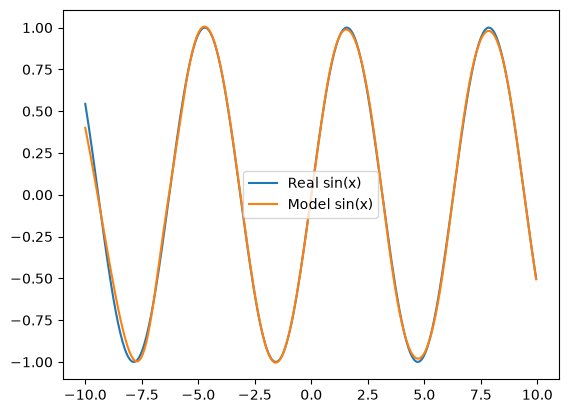

In [28]:
import matplotlib.pyplot as plt

model.eval()
with torch.no_grad():
    ypred = model(xtrain.to(device)).cpu().numpy()

plt.plot(xtrain.cpu().numpy(), ytrain.cpu().numpy(), label="Real sin(x)")
plt.plot(xtrain.cpu().numpy(), ypred, label="Model sin(x)")
plt.legend()
plt.show()

Remember these things while training NN models.
1. to change device to GPU, transfer only model, xtrain, ytrain to gpu and nothing else !
2. to change the input to torch tensor of float32 datatype and of 2 dims by view(-1,1)
3. define model before optimizer (because optimizer takes model.parameters() as inputs)

SOME DEEP NETWORKS : 

In [29]:
class MLP(nn.Module) : 
    def __init__(self, neurons_list : list, reg = True) : 
        super().__init__() # inheritance | python > 3 omits MLP, self in super() !
        modules = []
        for i in range(len(neurons_list)-1) : 
            modules.append(nn.Linear(neurons_list[i], neurons_list[i+1]))
            modules.append(nn.ReLU())
        if reg == True : 
            modules.pop()
        self.layers = nn.Sequential(*modules)
                
    def forward(self,x) : 
        out = self.layers(x)
        return out

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MLP([1,8,32,128,512,128,32,8,1]).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)


# lets fit a square wave with this MLP.
xtrain = np.arange(-10,10,0.05)
ytrain = np.sign(np.sin(2*xtrain))
xtrain = torch.tensor(xtrain, dtype=torch.float32).view(-1, 1)
ytrain = torch.tensor(ytrain, dtype=torch.float32).view(-1, 1)
xtrain = xtrain.to(device)
ytrain = ytrain.to(device)

epochs = 25000
for e in range(epochs) : 
    # forward pass
    outputs = model(xtrain)
    loss = criterion(outputs,ytrain)
    # backward pass
    optimizer.zero_grad() # this vanishes off grads of older backward passes
    loss.backward() # this calculates grads for this backward pass
    # weight update
    optimizer.step()
    print(f"epoch no. {e+1}, loss = {loss:.3f}")

epoch no. 1, loss = 1.133
epoch no. 2, loss = 1.034
epoch no. 3, loss = 2.950
epoch no. 4, loss = 1.035
epoch no. 5, loss = 1.058
epoch no. 6, loss = 1.088
epoch no. 7, loss = 1.090
epoch no. 8, loss = 1.084
epoch no. 9, loss = 1.078
epoch no. 10, loss = 1.072
epoch no. 11, loss = 1.064
epoch no. 12, loss = 1.054
epoch no. 13, loss = 1.042
epoch no. 14, loss = 1.027
epoch no. 15, loss = 1.012
epoch no. 16, loss = 1.005
epoch no. 17, loss = 1.012
epoch no. 18, loss = 1.013
epoch no. 19, loss = 1.005
epoch no. 20, loss = 0.999
epoch no. 21, loss = 0.997
epoch no. 22, loss = 0.997
epoch no. 23, loss = 0.997
epoch no. 24, loss = 0.997
epoch no. 25, loss = 0.996
epoch no. 26, loss = 0.994
epoch no. 27, loss = 0.992
epoch no. 28, loss = 0.990
epoch no. 29, loss = 0.987
epoch no. 30, loss = 0.984
epoch no. 31, loss = 0.981
epoch no. 32, loss = 0.978
epoch no. 33, loss = 0.974
epoch no. 34, loss = 0.970
epoch no. 35, loss = 0.965
epoch no. 36, loss = 0.959
epoch no. 37, loss = 0.951
epoch no. 

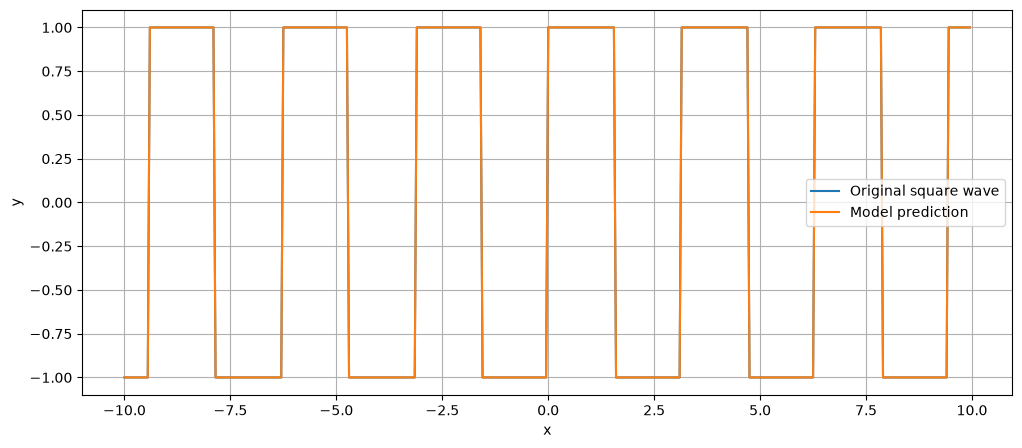

In [30]:
model.eval()
with torch.no_grad():
    ypred = model(xtrain.to(device)).cpu().numpy()

plt.figure(figsize=(12, 5))
plt.plot(xtrain.cpu().numpy(), ytrain.cpu().numpy(), label="Original square wave")
plt.plot(xtrain.cpu().numpy(), ypred, label="Model prediction")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid()
plt.show()

Lesson learnt is : use a sharp turn activation to fit a sharp turn function, 
smooth activation will give high errors over sharp turns.

NOW WE WILL START BASICS OF CNN (CONVOLUTIONAL NEURAL NETWORKS)

we will use handwritten digits dataset which is MNIST.
but first we need to know the dataset !

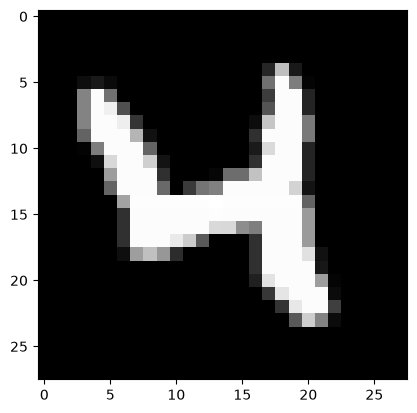

In [31]:
import torchvision.datasets as datasets
import torchvision.transforms as transforms

transform = transforms.ToTensor()
trainset = datasets.MNIST(root="./data",
                          train=True,
                          transform=transform)
testset = datasets.MNIST(root="./data",
                         train=False,
                         transform=transform)
plt.imshow(trainset[20][0].reshape(28,28),cmap="gray")

In [40]:
from torch.utils.data import DataLoader
bs = 100
train_load = DataLoader(dataset=trainset,
                                         batch_size=bs,
                                         shuffle=True)
test_load = DataLoader(dataset=testset,
                                        batch_size=bs,
                                        shuffle=True)
print(len(trainset), len(testset))
print(len(train_load), len(test_load))

60000 10000
600 100


In [41]:
class CNN(nn.Module) : 
    def __init__(self) : 
        super().__init__()
        self.conv = nn.Conv2d(in_channels=1, out_channels=8, kernel_size=3, stride=1, padding=1)
        self.relu = nn.ReLU()
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(8*28*28,10)
    def forward(self,x) : 
        out = self.conv(x)
        out = self.relu(out)
        out = self.flatten(out)
        out = self.fc(out)
        return out

In [42]:
print(device)

cuda


In [43]:
model = CNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)
for epoch in range(10) : 
    model.train()
    total_loss = 0
    for images, labels in train_load : 
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"epoch {epoch+1}, loss = {total_loss/len(train_load):.4f}")

epoch 1, loss = 0.3851
epoch 2, loss = 0.1952
epoch 3, loss = 0.1452
epoch 4, loss = 0.1123
epoch 5, loss = 0.0889
epoch 6, loss = 0.0729
epoch 7, loss = 0.0614
epoch 8, loss = 0.0514
epoch 9, loss = 0.0442
epoch 10, loss = 0.0389


In [44]:
model.eval()
correct = 0
total = 0 
with torch.no_grad() : 
    for images, labels in test_load:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (preds == labels).sum().item()
print(f"test acc = {100*correct/total:.2f}%")

test acc = 97.94%


NOW A DEEPER CNN FOR MNIST

In [45]:
class DeepCNN(nn.Module) : 
    def __init__(self) : 
        super().__init__()
        self.layers = nn.Sequential(nn.Conv2d(1, 32, kernel_size=3, padding=1),
                                    nn.BatchNorm2d(32),
                                    nn.ReLU(),
                        
                                    nn.Conv2d(32, 32, kernel_size=3, padding=1),
                                    nn.BatchNorm2d(32),
                                    nn.ReLU(),
                                    nn.MaxPool2d(2),  # (B, 32, 14, 14)
                        
                                    nn.Conv2d(32, 64, kernel_size=3, padding=1),
                                    nn.BatchNorm2d(64),
                                    nn.ReLU(),
                        
                                    nn.Conv2d(64, 64, kernel_size=3, padding=1),
                                    nn.BatchNorm2d(64),
                                    nn.ReLU(),
                                    nn.MaxPool2d(2),  # (B, 64, 7, 7),

                                    nn.Flatten(),
                                    nn.Linear(64*7*7,10))
    def forward(self,x) : 
        out = self.layers(x)
        return out

In [46]:
model = DeepCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)
for epoch in range(10) : 
    model.train()
    total_loss = 0
    for images, labels in train_load : 
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"epoch {epoch+1}, loss = {total_loss/len(train_load):.4f}")
model.eval()
correct = 0
total = 0 
with torch.no_grad() : 
    for images, labels in test_load:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (preds == labels).sum().item()
print(f"test acc = {100*correct/total:.2f}%")

epoch 1, loss = 0.1104
epoch 2, loss = 0.0395
epoch 3, loss = 0.0320
epoch 4, loss = 0.0251
epoch 5, loss = 0.0220
epoch 6, loss = 0.0179
epoch 7, loss = 0.0148
epoch 8, loss = 0.0139
epoch 9, loss = 0.0117
epoch 10, loss = 0.0095
test acc = 99.19%


NOW WE WILL BUILD DEEPER CNNs LIKE ResNet (Residual Network)
The problem with deeper cnns was : 
1. vanishing gradients
2. degradation problem
3. computational cost
ResNet solved all of these by using skip connections!

We will use CIFAR-100 to train our ResNet !!!

In [47]:
mean, std = (0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2762)

train_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
test_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

training_dataset = datasets.CIFAR100(root="./cifar100",
                                     train=True,
                                     download=True,
                                     transform=train_tf)
testing_dataset  = datasets.CIFAR100(root="./cifar100",
                                     train=False,
                                     download=True, 
                                     transform=test_tf)

train_loader = DataLoader(training_dataset, batch_size=128, shuffle=True)
test_loader  = DataLoader(testing_dataset,  batch_size=128, shuffle=False)

In [48]:
class ResidualBlock(nn.Module) : 
    def __init__(self,channels) : 
        super().__init__()
        self.block = nn.Sequential(nn.Conv2d(channels, channels, 3, 1, 1),
                                   nn.BatchNorm2d(channels),
                                   nn.ReLU(),
                                   nn.Conv2d(channels, channels, 3, 1, 1),
                                   nn.BatchNorm2d(channels))
        self.relu = nn.ReLU()
        
    def forward(self, x) : 
        out = self.block(x)
        out = out+x
        out = self.relu(out)
        return out

class ResNetCNN(nn.Module) : 
    def __init__(self) : 
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3,64,3,1,1,bias = False),
                                  nn.BatchNorm2d(64),
                                  nn.ReLU())

        self.res1 = ResidualBlock(64)
        self.res2 = ResidualBlock(64)

        self.pool1 = nn.MaxPool2d(2)
        self.conv1 = nn.Sequential(nn.Conv2d(64,128,3,1,1,bias=False),
                                  nn.BatchNorm2d(128),
                                  nn.ReLU())
        self.res3 = ResidualBlock(128)
        self.pool2 = nn.MaxPool2d(2)
        self.conv2 = nn.Sequential(nn.Conv2d(128,256,3,1,1,bias=False),
                                   nn.BatchNorm2d(256),nn.ReLU())
        self.res4 = ResidualBlock(256)
        self.pool3 = nn.AdaptiveAvgPool2d(1)
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(256,100)
    def forward(self,x) : 
        out = self.stem(x)
        out = self.res1(out)
        out = self.res2(out) 
        out = self.pool1(out) 
        out = self.conv1(out)
        out = self.res3(out)
        out = self.pool2(out)
        out = self.conv2(out)
        out = self.res4(out)
        out = self.pool3(out)
        out = self.flatten(out)
        out = self.fc(out)
        return out

device = "cuda" if torch.cuda.is_available() else "cpu"
model = ResNetCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=5e-2)

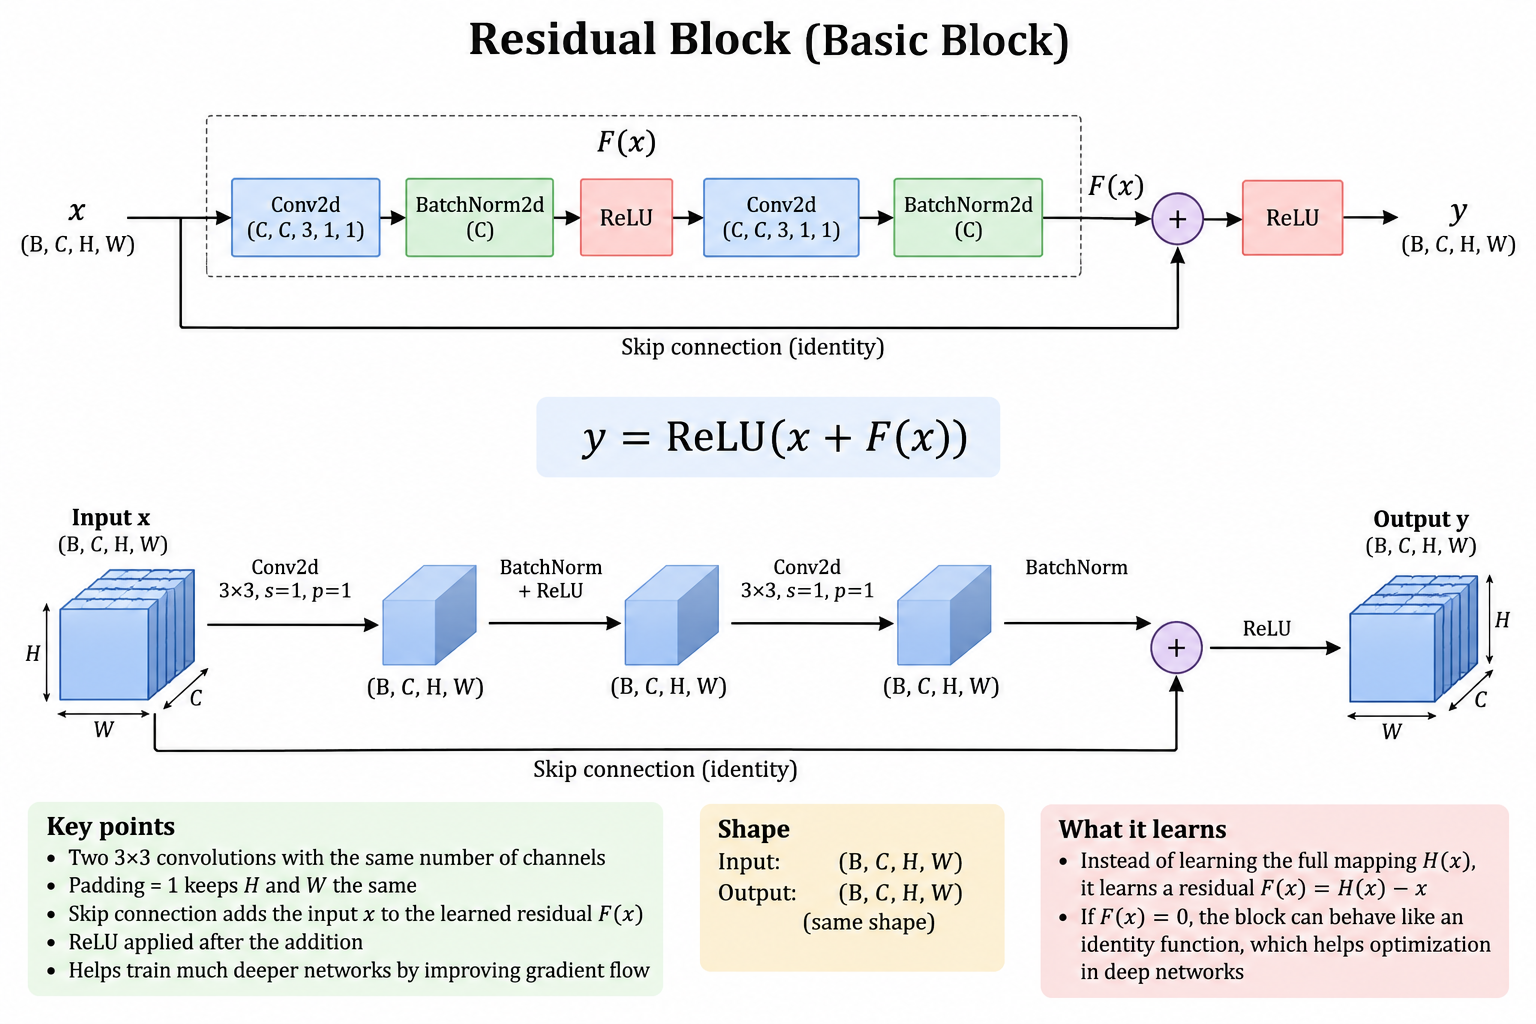

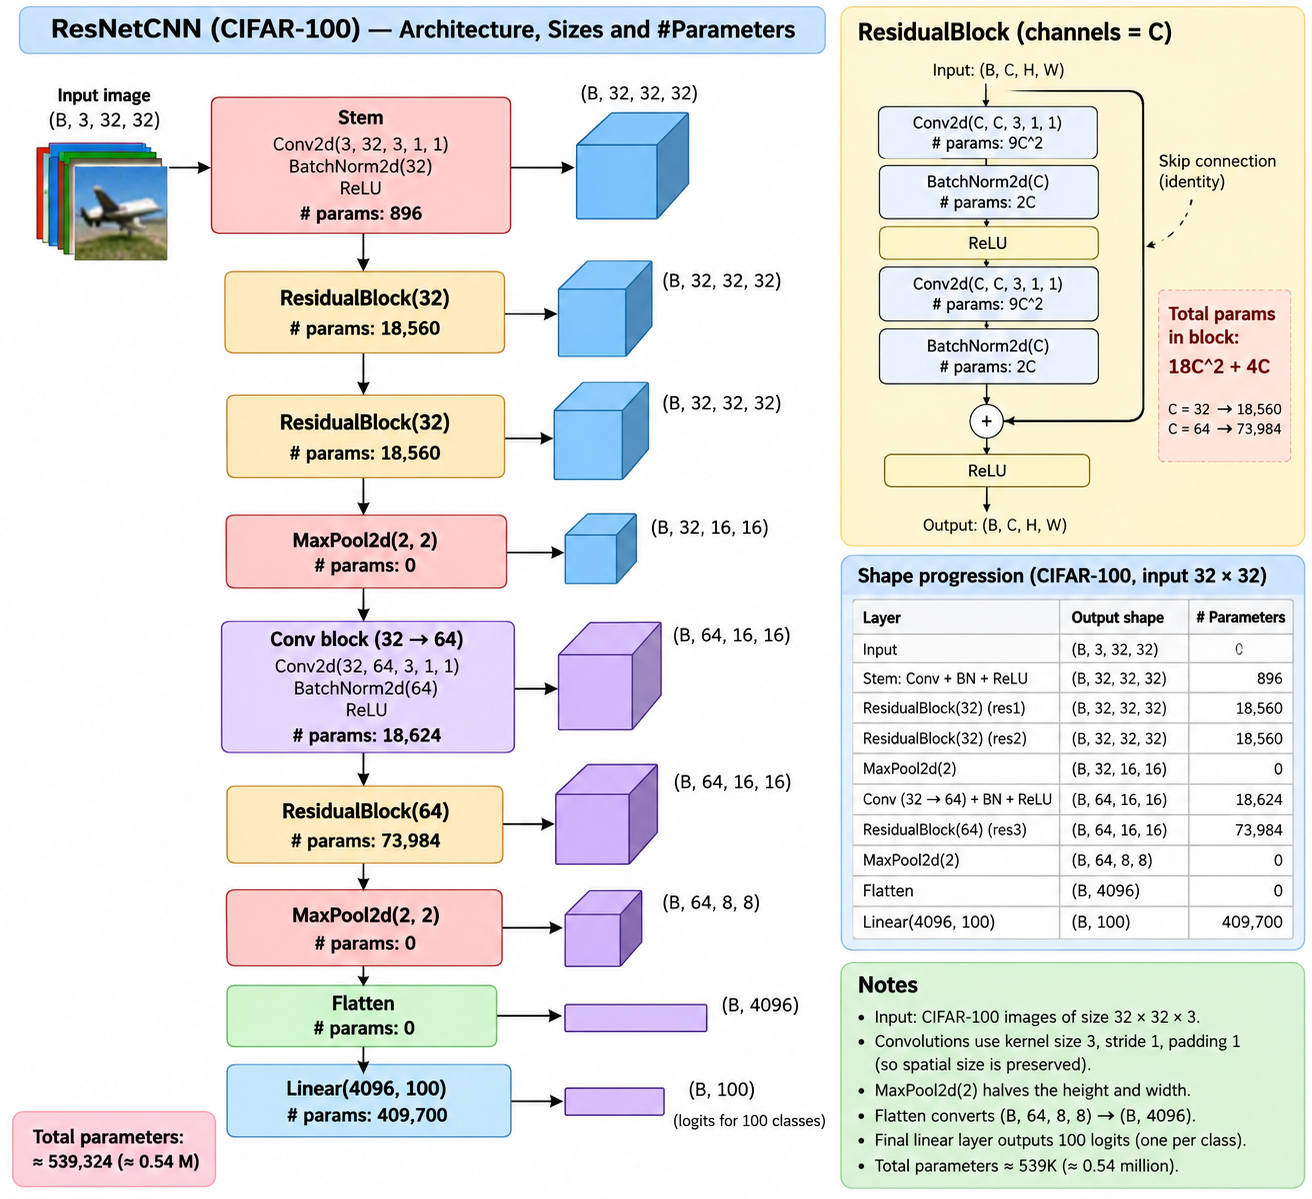

Older network that was underfitting !

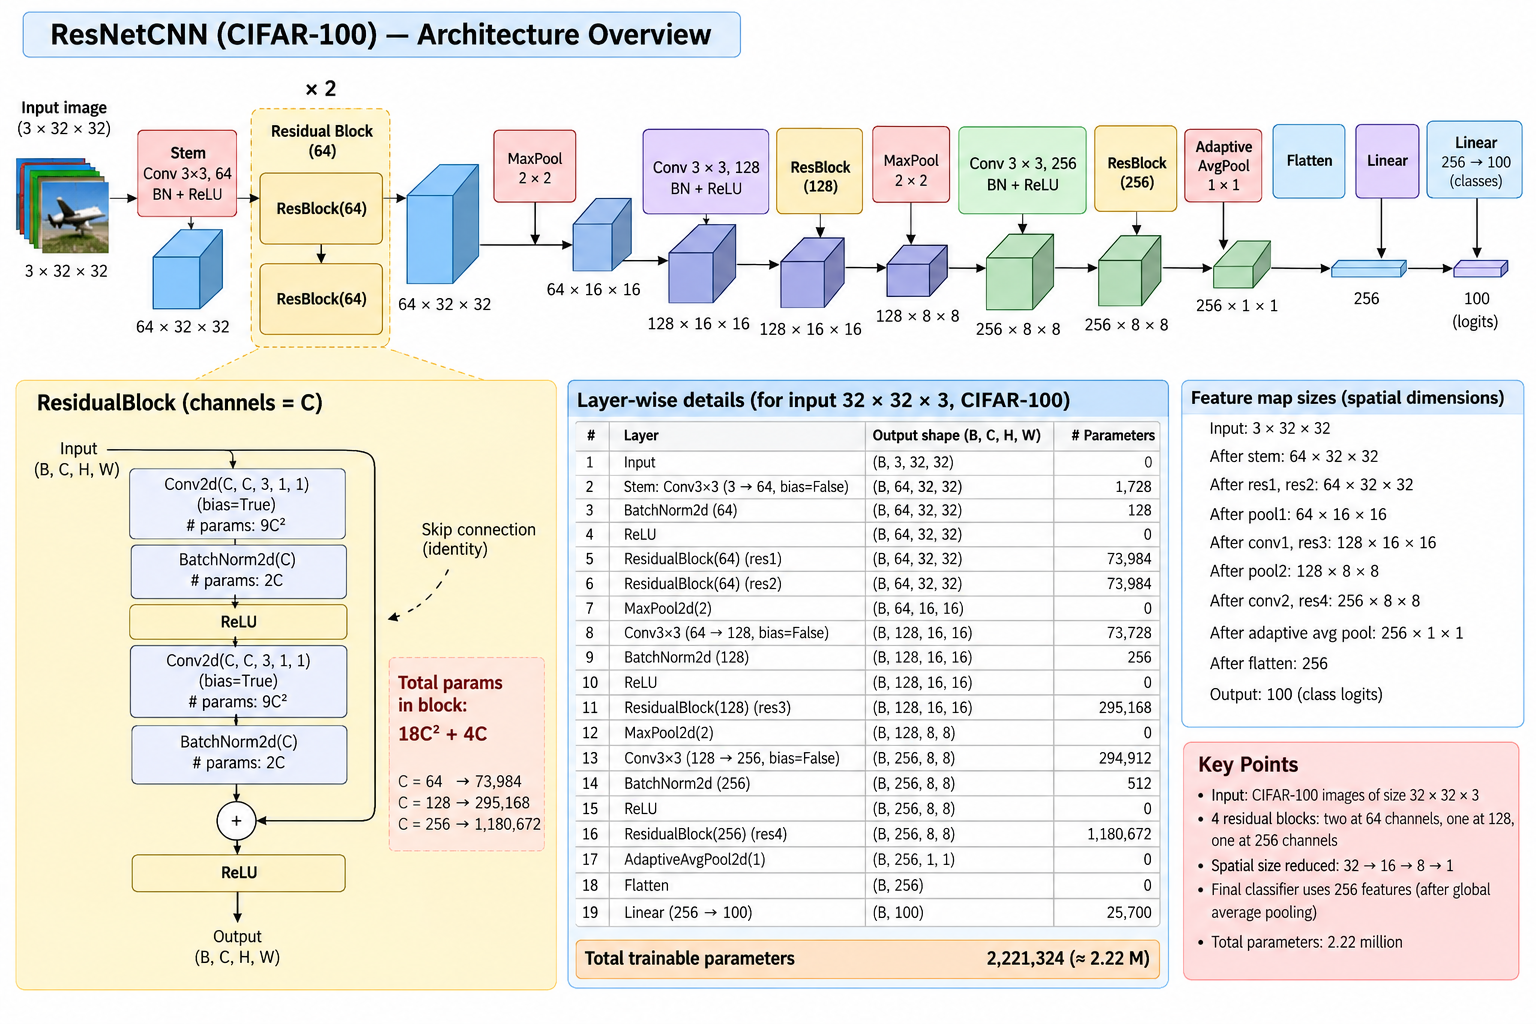 New Network that will fit more properly !


Remember some THUMB RULES : 
1. with cosine decay, longer runs almost always improve accuracy
2. train and test acc. both low : increase capacity (widen the network)
3. train acc high and test acc low : regularize/validate !

In [50]:
epochs = 5
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
for e in range(epochs) : 
    model.train()
    total_loss = 0
    for images, labels in train_loader : 
        images = images.to(device)
        labels = labels.to(device)

        preds = model(images)
        loss = criterion(preds, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    scheduler.step()
    print(f"epoch {e+1}, loss = {total_loss/len(train_loader):.3f}")

model.eval()
correct = 0
total = 0 
with torch.no_grad() : 
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (preds == labels).sum().item()
print(f"test acc = {100*correct/total:.2f}%")
    

epoch 1, loss = 1.024
epoch 2, loss = 0.931
epoch 3, loss = 0.818
epoch 4, loss = 0.685
epoch 5, loss = 0.590
test acc = 68.89%


WIDEN THE NETWORK WITH 512 DOWNSAMPLING LAYER AND ANOTHER POOL, CONV AND RES LAYER and see accuracy grow! also increase epochs, change data augmentation technique like crop, flip etc. this would alone lead to 85% accuracy which is very good !

Now we will learn transposed convolution !
basically if we have a 4x4 input and 3x3 kernel, with stride and padding 1 we need to slide kernel 4 times to produce the output of 2x2!!
so we will see it as input getting multiplied by an equivalent matrix that does the same job as sliding kernel! the equivalent matrix is called the convolution matrix!
size of this matrix is (sizex(nxsize))! here it will be 4x16 !
so we can say 4x16 (conv. matrix) times 16x1 (flattened input) gives 4x1 which then is converted to 2x2 !
no suppose 2x2 is input and we need to reach the 4x4 ! so transpose the convolution matrix and perform multiplication : 16x4 (transposed conv matrix) times 4x1 (flattened input) gives 16x1 input which then is converted to 4x4

we will call it CAE : convolutional auto encoder !

In [51]:
class CAE(nn.Module) : 
    def __init__(self) :
        super().__init__()
        self.encoder = nn.Sequential(nn.Conv2d(1,16,3,2,1),
                                     nn.ReLU(),
                                     nn.Conv2d(16,32,3,2,1),
                                     nn.ReLU())
        self.decoder = nn.Sequential(nn.ConvTranspose2d(32,16,3,2,1,output_padding=1),
                                     nn.ReLU(),
                                     nn.ConvTranspose2d(16,1,3,2,1,output_padding=1),
                                     nn.Sigmoid())
    def forward(self,x) : 
        out = self.encoder(x)
        out = self.decoder(out)
        return out

In [52]:
print(device)

cuda


In [53]:
transform = transforms.ToTensor()
trainset = datasets.MNIST(root="./data",
                          train=True,
                          transform=transform)
bs = 100
train_load = torch.utils.data.DataLoader(dataset=trainset,
                                         batch_size=bs,
                                         shuffle=True)
model = CAE().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)
epochs = 10
for e in range(epochs) : 
    model.train()
    total_loss = 0
    for images, _ in train_load : 
        images = images.to(device)
        reconstructed = model(images)
        loss = criterion(reconstructed, images)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"epoch {e+1}, loss = {total_loss/len(train_load):.4f}")

epoch 1, loss = 0.0206
epoch 2, loss = 0.0011
epoch 3, loss = 0.0008
epoch 4, loss = 0.0007
epoch 5, loss = 0.0006
epoch 6, loss = 0.0005
epoch 7, loss = 0.0005
epoch 8, loss = 0.0004
epoch 9, loss = 0.0004
epoch 10, loss = 0.0004


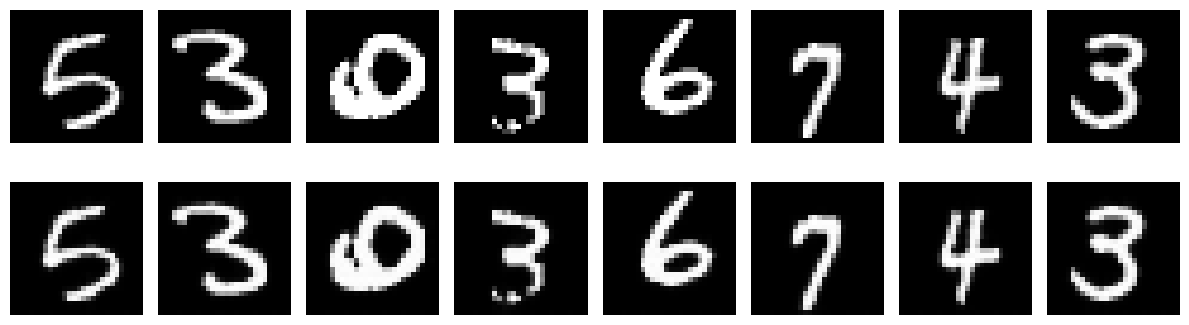

In [54]:
import matplotlib.pyplot as plt

model.eval()

images, _ = next(iter(DataLoader(testset, batch_size=8, shuffle=True)))
images = images.to(device)

with torch.no_grad():
    reconstructed = model(images)

fig, axes = plt.subplots(2, 8, figsize=(12, 4))

for i in range(8):
    axes[0, i].imshow(images[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstructed")

plt.tight_layout()
plt.show()

so our decoder layer just learnt to reconstruct the image from it's latent representation done by a previous encoder layer, we can even use this decoder layer to separately, feed it a random tensor of it's expected shape and get another representation but that won't look like a real digit of real life !!

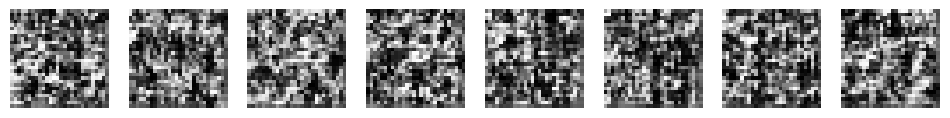

In [55]:
model.eval()
z = torch.randn(8,32,7,7).to(device)
with torch.no_grad() : 
    generated = model.decoder(z)
fig, axes = plt.subplots(1, 8, figsize=(12, 2))

for i in range(8):
    axes[i].imshow(generated[i].cpu().squeeze(), cmap="gray")
    axes[i].axis("off")

plt.show()

so does use of a decoder remains ? 
yes indeed! see a decoder is able to reconstruct from a latent represention without meaningful images from random noise,
lets try to give decoder a scaled and shifted latent representation of actual encoded mnist image and see what it generates !

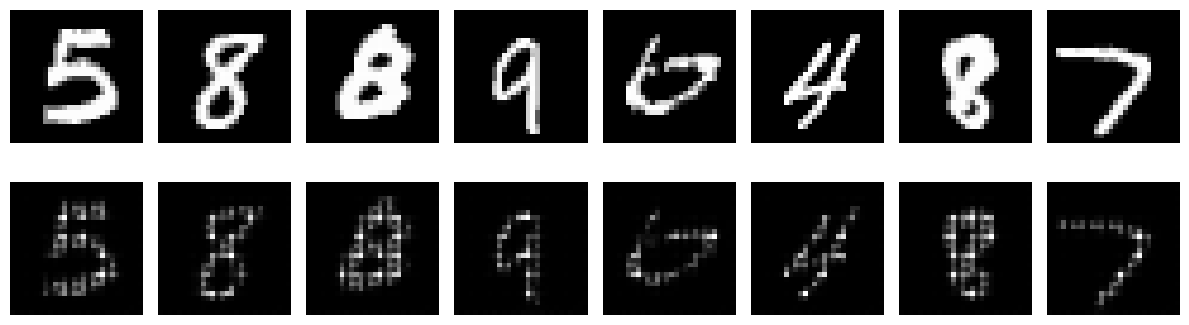

In [56]:
model.eval()

images, _ = next(iter(test_load))
images = images[:8].to(device)

with torch.no_grad():
    z = model.encoder(images)
    z_modified = 0.578 * z + 0.987
    generated = model.decoder(z_modified)

fig, axes = plt.subplots(2, 8, figsize=(12, 4))

for i in range(8):
    axes[0, i].imshow(images[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(generated[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Modified z")

plt.tight_layout()
plt.show()

see it gave us a real life meaningful image !
what CAE does is, it minimizes the reconstruction loss which has no explicit incentive to organize the latent space !
The CAE does not guarantee that the latent vectors between z1 and z2 decode into meaningful intermediate digits. Nor does it guarantee that random vectors decode into digits.

then came VAE, adding a constraint that encoder learn a probability distribution rathan than a fixed latent representation. instead of directly predicting latent vector, it predicts mean and variance. then it samples z = mean + stdev*x, x~N(0,I).
we force the encoder to produce specific probability distribution (gaussian generally) over encodings. the decoder will then sample the encodings from that probability distribution and try to reconstruct the image!

In [57]:
class VAE(nn.Module) : 
    def __init__(self, latent_dim = 20) : 
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(nn.Conv2d(1,16,3,2,1),
                                     nn.ReLU(),
                                     nn.Conv2d(16,32,3,2,1),
                                     nn.ReLU(),
                                     nn.Flatten())
        self.fc_mean = nn.Linear(32*7*7, latent_dim)
        self.fc_logvar = nn.Linear(32*7*7, latent_dim)
        self.fc_decode = nn.Linear(latent_dim, 32*7*7)
        self.decoder = nn.Sequential(nn.ConvTranspose2d(32,16,3,2,1,output_padding=1),
                                     nn.ReLU(),
                                     nn.ConvTranspose2d(16,1,3,2,1,output_padding=1),
                                     nn.Sigmoid())
        
    def reparameterize(self,mu,logvar) : 
        std = torch.exp(0.5*logvar)
        eps = torch.randn_like(std)
        return mu + std*eps

    def forward(self,x) :
        encoded = self.encoder(x)
        mu = self.fc_mean(encoded)
        logvar = self.fc_logvar(encoded)
        z = self.reparameterize(mu,logvar)
        decoded = self.fc_decode(z)
        decoded = decoded.view(-1,32,7,7)
        reconstructed = self.decoder(decoded)
        return reconstructed, mu, logvar

def vae_loss_fn(reconstructed, images, mu, logvar) : 
    reconstruction_loss = torch.nn.functional.binary_cross_entropy(reconstructed,
                                                                   images,
                                                                   reduction="sum")
    KLD_loss = -0.5*torch.sum(1+logvar-mu.pow(2) - logvar.exp())
    return reconstruction_loss+KLD_loss

In [58]:
model = VAE().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr = 0.01)
epochs = 20
for e in range(epochs) :
    model.train()
    total_loss = 0
    for images, _ in train_load : 
        images = images.to(device)
        recon, mu, logvar = model(images)
        loss = vae_loss_fn(recon, images, mu, logvar)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {e+1}/{epochs}, loss = {total_loss/len(train_load):.3f}")

Epoch 1/20, loss = 14015.077
Epoch 2/20, loss = 11250.164
Epoch 3/20, loss = 11056.081
Epoch 4/20, loss = 10961.248
Epoch 5/20, loss = 10903.040
Epoch 6/20, loss = 10861.622
Epoch 7/20, loss = 10822.097
Epoch 8/20, loss = 10801.789
Epoch 9/20, loss = 10778.781
Epoch 10/20, loss = 10755.396
Epoch 11/20, loss = 10748.437
Epoch 12/20, loss = 10740.096
Epoch 13/20, loss = 10719.694
Epoch 14/20, loss = 10718.159
Epoch 15/20, loss = 10710.459
Epoch 16/20, loss = 10691.252
Epoch 17/20, loss = 10690.376
Epoch 18/20, loss = 10676.933
Epoch 19/20, loss = 10677.739
Epoch 20/20, loss = 10672.594


Now lets plot what our VAE has learnt to decode !

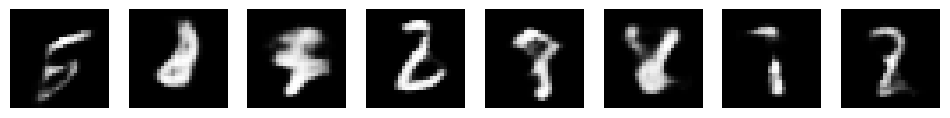

In [59]:
model.eval()

z = torch.randn(8, model.latent_dim).to(device)

with torch.no_grad():
    decoded = model.fc_decode(z)
    decoded = decoded.view(-1, 32, 7, 7)
    generated = model.decoder(decoded)

fig, axes = plt.subplots(1, 8, figsize=(12, 2))

for i in range(8):
    axes[i].imshow(generated[i].cpu().squeeze(), cmap="gray")
    axes[i].axis("off")

plt.show()

NOW ALL WE WERE DOING SO FAR WAS TAKING A DATASET, DESIGNING A MODEL FOR IT, AND TRANING IT FROM SCRATCH, BUT WHAT IF WE TAKE A PRETRAINED MODEL AND SOMEHOW MODIFY IT TO THE BEST OF OUR USE. 
IT'S CALLED Transfer Learning !
We can broadly classify layers of a CNN as Convolutional layers and Classification layers (the last fully connected layer)
here we can take two approaches,
A. freeze the weights of concolutional layers and train only the classification layer
B. unfreeze all and fine tune the complete model !

approach A is easy and requires less compute and gives better accuracy points per unit compute used!

In [60]:
from torchvision.models import resnet18, ResNet18_Weights
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)
for param in model.parameters() : 
    param.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, 100) #for example cifar100
# now just define train/test_loader, criterion, optimizer and start training !

now we will learn an interesting topic called neural style transfer!
see, a cnn learns different filters and features of an image ! what if we apply those learned filters of style image to our content image ?
this is called neural style transfer, an approach based on transfer learning itself!
we need to extract learnt features in between the layers of the model.

[NOT THAT IMPORTANT, SKIP IT]

Step 100, Loss: 7.7582
Step 200, Loss: 5.9122
Step 300, Loss: 4.9667
Step 400, Loss: 4.3651
Step 500, Loss: 3.9419
Step 600, Loss: 3.6235
Step 700, Loss: 3.3761
Step 800, Loss: 3.1794
Step 900, Loss: 3.0230
Step 1000, Loss: 2.8965


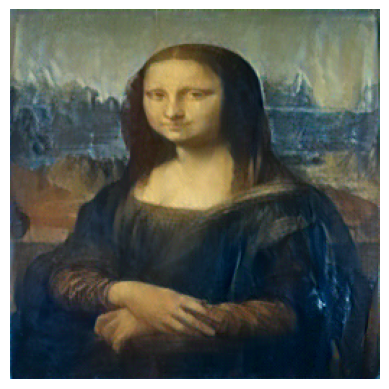

In [61]:
from torchvision.models import vgg19, VGG19_Weights
from PIL import Image
from torchvision import transforms

weights = VGG19_Weights.DEFAULT
vgg = vgg19(weights=weights).features.to(device)
for param in vgg.parameters() : 
    param.requires_grad = False
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def load_image(path):
    image = Image.open(path).convert("RGB")
    image = transform(image).unsqueeze(0)
    return image.to(device)

content = load_image("content.jpg")
style = load_image("style.jpg")

def get_features(image):
    features = {}
    layers = {
        "0": "conv1_1",
        "5": "conv2_1",
        "10": "conv3_1",
        "19": "conv4_1",
        "21": "content"
    }

    x = image

    for name, layer in vgg._modules.items():
        x = layer(x)
        if name in layers:
            features[layers[name]] = x

    return features

def gram_matrix(features):
    batch, channels, height, width = features.shape
    features = features.view(batch, channels, height * width)
    gram = torch.bmm(features, features.transpose(1, 2))
    return gram / (channels * height * width)

content_features = get_features(content)
style_features = get_features(style)

style_grams = {
    layer: gram_matrix(style_features[layer])
    for layer in style_features
    if layer != "content"
}
generated = content.clone().requires_grad_(True)

optimizer = torch.optim.Adam([generated], lr=0.003)

style_weight = 1e6
content_weight = 1

style_layers = ["conv1_1", "conv2_1", "conv3_1", "conv4_1"]

for step in range(1000):
    generated_features = get_features(generated)

    content_loss = nn.functional.mse_loss(
        generated_features["content"],
        content_features["content"]
    )

    style_loss = 0

    for layer in style_layers:
        generated_gram = gram_matrix(generated_features[layer])
        style_loss += nn.functional.mse_loss(
            generated_gram,
            style_grams[layer]
        )

    total_loss = content_weight * content_loss + style_weight * style_loss

    optimizer.zero_grad()
    total_loss.backward()
    optimizer.step()

    if (step + 1) % 100 == 0:
        print(f"Step {step+1}, Loss: {total_loss.item():.4f}")

mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

result = (generated.detach() * std + mean).clamp(0, 1)
result = result.squeeze(0).permute(1, 2, 0).cpu()

plt.imshow(result)
plt.axis("off")
plt.show()

SO FAR WE ARE LEARNING ABOUT IMAGES, LETS PROCESS SOME TEXT THROUGH NEURAL NETWORKS.
IN A TYPICAL LINE, ORDER OF THE WORDS MATTERS ! SO RNNs WERE BUILT TO PREDICT THE NEXT WORD IN SENTENCE WHICH REQUIRE PROCESSING THE PRECEDING WORDS! RNNs maintain a hidden state that carries information from earlier timesteps !

CNNs were made specially to recognize spatial patterns like edges, textures, shapes, objects!
The issue was not that CNNs couldn't process sequences at all but ordinaryf feedforward networks don't inherently maintain a recurrent state that carries information further to next timesteps!
lets build a simpel RNN with mnist data as a sequence !
we treated mnist data as (B,T,H) = (64 batched, 28 rows, 28 values per row)
so 28 timestep will be created and it will try to learn relationship between each row for the prediction.
also since pixel row in not naturally sequential we will not get phenomenal results out of this model !

In [62]:
class RNN(nn.Module) : 
    def __init__(self) : 
        super().__init__()
        self.rnn = nn.RNN(input_size = 28,
                          hidden_size = 128,
                          num_layers = 1,
                          batch_first = True)
        self.fc = nn.Linear(128,10)

    def forward(self,x) : 
        out,h = self.rnn(x)
        out = self.fc(out[:,-1,:])
        return out

In [63]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.ToTensor()

trainset = datasets.MNIST(
    root="./mnist", train=True, transform=transform)
testset = datasets.MNIST(
    root="./mnist", train=False, transform=transform)

train_loader = DataLoader(trainset, batch_size=64, shuffle=True)
test_loader = DataLoader(testset, batch_size=64, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [64]:
model = RNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
epochs = 5

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for images, labels in train_loader:
        images = images.squeeze(1).to(device)
        labels = labels.to(device)

        preds = model(images)
        loss = criterion(preds, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss/len(train_loader):.4f}")

Epoch 1/5, Loss: 0.7427
Epoch 2/5, Loss: 0.3125
Epoch 3/5, Loss: 0.2372
Epoch 4/5, Loss: 0.1991
Epoch 5/5, Loss: 0.1759


In [65]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.squeeze(1).to(device)
        labels = labels.to(device)

        preds = model(images)
        predicted = preds.argmax(dim=1)

        correct += (predicted == labels).sum().item()
        total += labels.size(0)

print(f"Test Accuracy: {100 * correct / total:.2f}%")

Test Accuracy: 96.02%


an RNN can learn relationship between sequences to predict the next one which is of no use in mnist dataset because they not naturally sequential !!!

In [66]:
!wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

--2026-10-18 19:10:52--  https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1115394 (1.1M) [text/plain]
Saving to: ‘input.txt.1’

input.txt.1         100%[===================>]   1.06M  --.-KB/s    in 0.08s   

2026-10-18 19:10:52 (14.1 MB/s) - ‘input.txt.1’ saved [1115394/1115394]



In [67]:
with open("input.txt", "r", encoding="utf-8") as f : 
    text = f.read()
chars = sorted(set(text))
vocab_size = len(chars) 
chartoidx = {ch:i for i, ch in enumerate(chars)}
idxtochar = {i:ch for i,ch in enumerate(chars)}
data = torch.tensor([chartoidx[ch] for ch in text])
print(f"total chars : {len(text)}, vocab size : {vocab_size}")

total chars : 1115394, vocab size : 65


In [68]:
sequence_length = 100

def get_batch(batch_size = 64) : 
    starts = torch.randint(0,len(data)-sequence_length-1,(batch_size,))
    x = torch.stack([data[i:i+sequence_length] for i in starts])
    y = torch.stack([data[i+1:i+sequence_length+1] for i in starts])
    return x,y
x,y = get_batch()

print(f"input shape : {x.shape}, output shape : {y.shape}")

input shape : torch.Size([64, 100]), output shape : torch.Size([64, 100])


In [69]:
class DeepRNN(nn.Module) : 
    def __init__(self, vocab_size, embedding_dim = 64, hidden_size = 256, layers = 3) :
        super().__init__() 
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.rnn = nn.RNN(input_size=embedding_dim,
                          hidden_size=hidden_size,
                          num_layers = layers,
                          batch_first = True, 
                          dropout = 0.2)
        self.fc = nn.Linear(hidden_size,vocab_size)

    def forward(self,x) : 
        out = self.embedding(x)
        out, h = self.rnn(out)
        out = self.fc(out)
        return out

In [70]:
model = DeepRNN(vocab_size).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)
print(model)

DeepRNN(
  (embedding): Embedding(65, 64)
  (rnn): RNN(64, 256, num_layers=3, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=256, out_features=65, bias=True)
)


In [71]:
epochs = 10
batch_size = 64
steps_per_epoch = 500

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for _ in range(steps_per_epoch):
        x, y = get_batch(batch_size)
        x = x.to(device)
        y = y.to(device)

        outputs = model(x)

        loss = criterion(
            outputs.reshape(-1, vocab_size),
            y.reshape(-1)
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss/steps_per_epoch:.4f}")

Epoch 1/10, Loss: 2.0078
Epoch 2/10, Loss: 1.6334
Epoch 3/10, Loss: 1.5461
Epoch 4/10, Loss: 1.5026
Epoch 5/10, Loss: 1.4758
Epoch 6/10, Loss: 1.4551
Epoch 7/10, Loss: 1.4392
Epoch 8/10, Loss: 1.4272
Epoch 9/10, Loss: 1.4195
Epoch 10/10, Loss: 1.4110


In [72]:
def generate_char(model, start_text, length = 500, temprature = 0.8) : 
    model.eval()
    input_ids = torch.tensor([[chartoidx[ch] for ch in start_text]], 
    dtype=torch.long,
    device = device)
    generated = start_text
    with torch.no_grad() : 
        for _ in range(length) : 
            outputs = model(input_ids)
            logits = outputs[:,-1,:]/temprature
            probs = torch.softmax(logits, dim=-1)
            next_char = torch.multinomial(probs, num_samples = 1)
            next_id = next_char.item()
            generated += idxtochar[next_id]
            input_ids = torch.cat([input_ids, next_char], dim = 1)
        return generated

print(generate_char(model, "ROMEO:", length=500))

ROMEO:
I will put them, his better gliff!

DUKE VINCENTIO:
The cry in my wind, that their worst from him, and tender with
me?

CORIOLANUS:
I would dead made his head, farewell did she was from the more
being, and their adverses to a mistressing there?

All:
Ay, this life with much before a
can a lamms, and bid it well; sweet a fair son home; there we will rother light.

CAMILLO:
A letterly please this mother is a strength, hence will proclaim with yourncident
his proper, would came of him--me off. How


Like DeepCNNs the problem is vanishing gradients ! and the solution to overcome the problem is to use skip connections ! so that model does not forget about older context ! but it's not quite literally passing an older hidden state to the latest iteration because we are propagating in time and not through layers, LSTM instead maintains two states from start of the time namely hidden and cell state using three gates forget, input and output!
they decide what to forget from old memory, how much importance to give to current input and what to expose to next hidden state !

In [76]:
# i will train a deep lstm for now because the main difference will be the
# num_layers arg (which would be 1 if it was a normal lstm) and no dropout arg !
class LSTM(nn.Module) : 
    def __init__(self, vocab_size, embedding_dim = 64, hidden_size = 256) : 
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.lstm = nn.LSTM(input_size = embedding_dim,hidden_size=hidden_size,
        num_layers = 3, batch_first = True, dropout = 0.2)
        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self,x) : 
        out = self.embedding(x) 
        out, (h,c) = self.lstm(out)
        out = self.fc(out)
        return out

In [77]:
model = LSTM(vocab_size).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 10
batch_size = 64
steps_per_epoch = 500

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for _ in range(steps_per_epoch):
        x, y = get_batch(batch_size)
        x = x.to(device)
        y = y.to(device)

        outputs = model(x)

        loss = criterion(
            outputs.reshape(-1, vocab_size),
            y.reshape(-1)
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss/steps_per_epoch:.4f}")

Epoch 1/10, Loss: 2.4565
Epoch 2/10, Loss: 1.7972
Epoch 3/10, Loss: 1.6147
Epoch 4/10, Loss: 1.5219
Epoch 5/10, Loss: 1.4622
Epoch 6/10, Loss: 1.4194
Epoch 7/10, Loss: 1.3845
Epoch 8/10, Loss: 1.3590
Epoch 9/10, Loss: 1.3353
Epoch 10/10, Loss: 1.3174


In [80]:
print(generate_char(model, "ROMEO:", length=500, temprature=0.8))

ROMEO:
Thou didst fell thee to me at a thousand to the gitter.
Pray the world better hears in hands he hath?

SICINIUS:
Warwick! Play, stis Lord York; let thee for't
As thou wilt be aughter made persons
And then keep you to death to break it,
That this world like unto the world ne'er
But they mine own battle, provide a sight.

HENRY BOLINGBROKE:
Marcius, and heavy silver say Friar.

QUEEN ELIZABETH:
Why, in God's grave ladies flowers.

DUKE VINCENTIO:
Why, my lord, they doth disposition,
A man go thy 


We can also train bidirectional lstms and rnns ! we just have to add an argument 
bidirectional = True in the nn.RNN/LSTM !! this helps in accuracy since model knows the future words also !
Understanding/classifying an already-known sequence: bidirectional can be very useful.

now lstms were far more computaionally expensive than rnns so grus were introduced they perform on par with lstms but very less computationally expensive. 
they maintain only one state with two gates.

In [85]:
class GRU(nn.Module):
    def __init__(self, vocab_size, embedding_dim=64, hidden_size=256):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_size,
            num_layers=3,
            batch_first=True,
            dropout = 0.2
        )
        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, x):
        x = self.embedding(x)
        out, h = self.gru(x)
        return self.fc(out)

In [86]:
model = GRU(vocab_size).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 10
batch_size = 64
steps_per_epoch = 500

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for _ in range(steps_per_epoch):
        x, y = get_batch(batch_size)
        x = x.to(device)
        y = y.to(device)

        outputs = model(x)

        loss = criterion(
            outputs.reshape(-1, vocab_size),
            y.reshape(-1)
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss/steps_per_epoch:.4f}")

Epoch 1/10, Loss: 1.9960
Epoch 2/10, Loss: 1.5038
Epoch 3/10, Loss: 1.4100
Epoch 4/10, Loss: 1.3611
Epoch 5/10, Loss: 1.3326
Epoch 6/10, Loss: 1.3111
Epoch 7/10, Loss: 1.2931
Epoch 8/10, Loss: 1.2808
Epoch 9/10, Loss: 1.2674
Epoch 10/10, Loss: 1.2582


In [87]:
print(generate_char(model, "ROMEO:", length=500, temprature=0.8))

ROMEO:
Nay, the sun.

AUFIDIUS:
Sir, here we may be patient!

BUCKINGHAM:
To yourself, provoke thee that you are not, or wretch,
And hear the bride conjured I dare go fear
Your love, would live, unrevenue. I will leave the dead,
I will show thy mind by a while we have meet
A person she loves within the prince, whiphed
Than carry his voices, they are some minds;
For then, she was not the bosom of me as yourself:
And therefore let him be pantity to be gone.
If they do, wrong! Your guilty prince and secr


predicting next character is ok but what if we have to predict next word ?
we use word embedding models for it !

In [92]:
import torch.nn.functional as F
import torch.optim as optim
word_to_idx = {"i" : 0, "like" : 1, "to" : 2, "eat" : 3, "and" : 4, "sleep" : 5}
embeddings = nn.Embedding(len(word_to_idx),embedding_dim=7)
word_index = torch.tensor([word_to_idx["like"]])
print(word_index)
like = embeddings(word_index)
print(like)
print(like.shape)
# same we can do with all the words !

tensor([1])
tensor([[-0.9252, -0.1030, -0.3911, -0.2344, -1.1900, -1.0810, -0.4152]],
       grad_fn=<EmbeddingBackward0>)
torch.Size([1, 7])


Remember that these encodings are local to the context/model, means these are not universal encodings! while trainig a model the encoding matrix can change by backpropagation !

In [93]:
print(torch.cuda.memory_summary())

|===========================================================================|
|                  PyTorch CUDA memory summary, device ID 0                 |
|---------------------------------------------------------------------------|
|            CUDA OOMs: 0            |        cudaMalloc retries: 0         |
|===========================================================================|
|        Metric         | Cur Usage  | Peak Usage | Tot Alloc  | Tot Freed  |
|---------------------------------------------------------------------------|
| Allocated memory      | 263590 KiB | 654777 KiB |  41470 GiB |  41470 GiB |
|       from large pool | 233353 KiB | 644864 KiB |  41024 GiB |  41023 GiB |
|       from small pool |  30237 KiB |  46498 KiB |    446 GiB |    446 GiB |
|---------------------------------------------------------------------------|
| Active memory         | 263590 KiB | 654777 KiB |  41470 GiB |  41470 GiB |
|       from large pool | 233353 KiB | 644864 KiB |  41024 GiB |

Now we will start something called sequence modelling. It uses RNNs and is called Seq2Seq prediction ! it is task of learning pattern in ordered data so that the model can predict/classify. lets first try to learn sinusoidal wave through RNNs.

In [4]:
import torch
import torch.nn as nn
import math

device = "cuda"
t = torch.linspace(0,100,2000)
data = torch.sin(t).unsqueeze(1)
seq_length = 30
X = torch.stack([data[i:i+seq_length] for i in range(len(data)-seq_length)])
Y = torch.stack([data[i+seq_length] for i in range(len(data) - seq_length)])
split = int(0.8 * len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = Y[:split], Y[split:]

X_train, X_test = X_train.to(device), X_test.to(device)
y_train, y_test = y_train.to(device), y_test.to(device)

print(X_train.shape)
print(y_train.shape)

torch.Size([1576, 30, 1])
torch.Size([1576, 1])


In [5]:
class SequenceModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(
            input_size=1,
            hidden_size=32,
            batch_first=True
        )
        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        out, hidden = self.rnn(x)
        return self.fc(out[:, -1, :])

model = SequenceModel().to(device)

In [6]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

for epoch in range(50):
    model.train()

    optimizer.zero_grad()
    predictions = model(X_train)
    loss = criterion(predictions, y_train)
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1}, Loss: {loss.item():.6f}")

Epoch 10, Loss: 0.283374
Epoch 20, Loss: 0.076762
Epoch 30, Loss: 0.043886
Epoch 40, Loss: 0.017932
Epoch 50, Loss: 0.012115


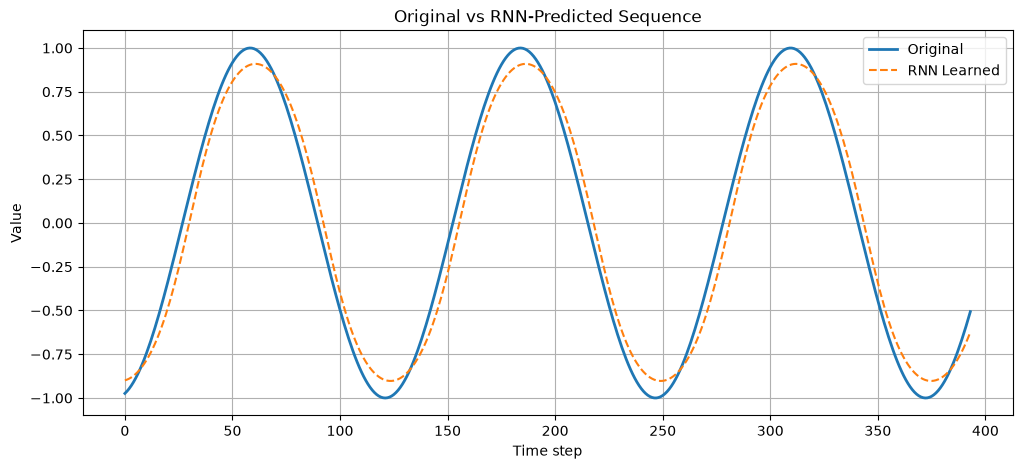

In [7]:
import matplotlib.pyplot as plt

model.eval()

with torch.no_grad():
    predictions = model(X_test).cpu().numpy()

original = y_test.cpu().numpy()

plt.figure(figsize=(12, 5))
plt.plot(original, label="Original", linewidth=2)
plt.plot(predictions, label="RNN Learned", linestyle="--")
plt.xlabel("Time step")
plt.ylabel("Value")
plt.title("Original vs RNN-Predicted Sequence")
plt.legend()
plt.grid(True)
plt.show()

test it with nn.LSTM, you will get a more accurate curve !

Now there is still a bottleneck to it ! what if we have a long paragraph of say 1000 words! LSTMs and GRUs process sequence one at a time and carry forward the information through reccurent states.
This is the key motivation for attention: what if the decoder didn't have to rely on just one summary of the input?

Instead, what if it could look back at the encoder's different time-step representations and focus on the most relevant ones while generating each output word?